---
title: "Wycena opcji barierowej Down-and-Out Put za pomocą PyMPDATA"
author: "Kamil Kasperek"
lang: pl
format:
  pdf:
    geometry: margin=0.55in
    fontsize: 9.5pt
    echo: false
    warning: false
---

### Cel pracy i pytanie badawcze
Celem eksperymentu jest numeryczna wycena europejskiej opcji sprzedaży z dolną barierą wyłączającą (**Down-and-Out Put**) poprzez sprowadzenie modelu Blacka-Scholesa do równania adwekcji-dyfuzji i rozwiązanie go w bibliotece `PyMPDATA`. 

**Pytanie badawcze:** *Jak dobrze schemat 2. rzędu `MPDATA` radzi sobie ze stromym spadkiem wartości przy barierze $B$ oraz wyznaczeniem współczynnika Delta ($\Delta = \partial V / \partial S$) na różnych rozdzielczościach siatki w porównaniu ze zwykłym schematem `upwind`?*

In [1]:
import sys
if 'google.colab' in sys.modules:
    !pip --quiet install open-atmos-jupyter-utils
    from open_atmos_jupyter_utils import pip_install_on_colab
    pip_install_on_colab('PyMPDATA-examples')

In [2]:
import numpy as np
from matplotlib import pyplot
from open_atmos_jupyter_utils import show_plot, show_anim
from PyMPDATA import ScalarField, Solver, Stepper, VectorField, Options, boundary_conditions
from scipy.special import erf

## 1. Podejście numeryczne i wzorzec analityczny

Równanie Blacka-Scholesa po przejściu na zmienną logarytmiczną $x = \ln(S/K)$ oraz czas wsteczny $\tau = T - t$ przyjmuje postać 1D równania adwekcji-dyfuzji, gdzie dyfuzja odpowiada zmienności $\sigma$, a adwekcja dryfowi rynkowemu. Barierę wyłączającą $B$ modelujemy jako pochłaniający warunek brzegowy Dirichleta ($\psi = 0$ dla $S \le B$), a człon dyfuzyjny realizujemy w `PyMPDATA` przez pseudo-prędkość dyfuzyjną z zachowaniem warunku stabilności Couranta ($|C| \le 1$).

Jako punkt odniesienia wykorzystano ścisły wzór analityczny (Wilmott i in., 1995), który odejmuje od wyceny zwykłej opcji *Put* jej odbicie względem bariery $B$.

# Jezcze można ttuaj poprosotu co to wgle jest down-and-out put option

In [3]:
class DownAndOutPutIntegrator:
    def __init__(self, *, strike_price, barrier_price, volatility, risk_free_interest_rate, nx, options = None):
        options = options or Options(nonoscillatory=True, infinite_gauge=True)
        
        self.K = strike_price
        self.B = barrier_price
        self.r = risk_free_interest_rate
        self.sigma = volatility

        x_min = np.log(self.B / self.K)
        x_max = max(4.0 * np.log(self.K / self.B), 1.5)
        self.dx = (x_max - x_min) / nx
        self.x = x_min + (np.arange(nx) + 0.5) * self.dx
        self.S = self.K * np.exp(self.x)

        payout = np.where((self.B < self.S) & (self.S < self.K), self.K - self.S, 0.0)
        common = {
            'halo' : options.n_halo,
            'boundary_conditions' : (boundary_conditions.Constant(value=0),)
        }
        
        self.advectee = ScalarField(**common, data=payout)
        self.advector = VectorField(**common, data=(np.zeros(nx + 1),))
        self.solver = Solver(advector=self.advector, advectee=self.advectee, stepper=Stepper(n_dims=1, options=options))

    def _update_courant_numbers(self, *, dt, eps=1e-12):
        psi = self.advectee.get()
        psi_padded = np.pad(psi, 1, constant_values=0.0)
        c_adv = (0.5 * self.sigma**2 - self.r) * dt / self.dx
        lambda_sq = 0.5 * self.sigma**2 * dt / (self.dx**2)
        c_diff = -lambda_sq * np.diff(psi_padded) / (0.5 * (psi_padded[1:] + psi_padded[:-1]) + eps)
        courant = self.advector.get_component(0)
        courant[:] = c_adv + c_diff
        
        assert np.amax(np.abs(courant)) <= 1.0

    def __call__(self, *, nt, T, outfreq, eps=1e-7):
        dt = T / nt
        output = []
        for it in range(nt + 1):
            if it != 0:
                self._update_courant_numbers(dt=dt)
                self.solver.advance(n_steps=1)
            if it % outfreq == 0:
                output.append(self.advectee.get().copy() * np.exp(-self.r * it * dt))
        return output

In [4]:
def AnalyticalDownAndOutPutSolver(S, K, B, T, r, sigma):
    def N(z):
        return 0.5 * (1.0 + erf(z / np.sqrt(2.0)))

    def vanilla_put(s, strike):
        d1 = (np.log(s / strike) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
        d2 = d1 - sigma * np.sqrt(T)
        return strike * np.exp(-r * T) * N(-d2) - s * N(-d1)

    def binary_put(s, strike):
        d2 = (np.log(s / strike) + (r - 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
        return np.exp(-r * T) * N(-d2)

    def truncated_put(s):
        return vanilla_put(s, K) - vanilla_put(s, B) - (K - B) * binary_put(s, B)

    power = 2.0 * r / (sigma**2) - 1.0
    result = truncated_put(S) - (B / S)**power * truncated_put((B**2) / S)
    return np.where(S > B, result, 0.0)

In [5]:
def plot_results(integ_MPDATA, output_MPDATA, output_upwind, nx, nt):
    S = integ_MPDATA.S
    S_plot = np.concatenate(([60.0, barrier_price], S))
    pad_zeros = lambda arr: np.concatenate(([0.0, 0.0], arr))
    
    analytical_price = AnalyticalDownAndOutPutSolver(S, strike_price, barrier_price, T, risk_free_interest_rate, volatility)
    analytical_delta = np.gradient(analytical_price, S)
    mpdata_delta = np.gradient(output_MPDATA[-1], S)
    upwind_delta = np.gradient(output_upwind[-1], S)
    
    fig, (ax_price, ax_delta) = pyplot.subplots(1, 2, figsize=(11, 3.5))
    
    ax_price.plot(S_plot, pad_zeros(output_MPDATA[0]), linestyle=':', color='gray', label='Payout (t = T)')
    ax_price.plot(S_plot, pad_zeros(output_MPDATA[len(output_MPDATA) // 2]), linestyle='-.', color='tab:cyan', label='MPDATA (t = 0.5 T)')
    ax_price.plot(S_plot, pad_zeros(output_upwind[len(output_upwind) // 2]), linestyle='-.', color='tab:orange', label='upwind (t = 0.5 T)')
    ax_price.plot(S_plot, pad_zeros(output_upwind[-1]), linestyle='--', color='tab:red', label='Upwind (t = 0)')
    ax_price.plot(S_plot, pad_zeros(output_MPDATA[-1]), color='tab:blue', linewidth=2, label='MPDATA (t = 0)')
    ax_price.plot(S_plot, pad_zeros(analytical_price), linestyle='--', color='black', linewidth=1.2, label='Analytical (t = 0)')
    ax_price.axvline(barrier_price, color='green', linestyle='--', linewidth=1, label=f'Barrier B = {barrier_price}$')
    ax_price.set_xlim(75, 160)
    ax_price.set_xlabel('Price of asset S [$]')
    ax_price.set_ylabel('Value of option f(S, t) [$]')
    ax_price.set_title(f'Evolution of the premium (nx={nx}, nt={nt})')
    ax_price.grid(True, alpha=0.3)
    ax_price.legend(fontsize=8)
    
    ax_delta.plot(S, upwind_delta, linestyle='--', color='tab:orange', label='Upwind (t = 0)')
    ax_delta.plot(S, mpdata_delta, color='tab:blue', linewidth=2, label='MPDATA (t = 0)')
    ax_delta.plot(S, analytical_delta, linestyle='--', color='black', linewidth=1.2, label='Analytical (t = 0)')
    ax_delta.axvline(barrier_price, color='green', linestyle='--', linewidth=1, label=f'Barrier B = {barrier_price}$')
    ax_delta.axhline(0, color='gray', linewidth=0.8)
    ax_delta.set_xlim(75, 160)
    ax_delta.set_xlabel('Price of asset S [$]')
    ax_delta.set_ylabel('Delta Δ = ∂f / ∂S [-]')
    ax_delta.set_title(f'Wallet sensitivity (Delta hedging) (nx={nx}, nt={nt})')
    ax_delta.grid(True, alpha=0.3)
    ax_delta.legend(fontsize=8)
    
    pyplot.tight_layout()
    show_plot('down_and_out_put')

## 2. Wyniki symulacji dla różnych rozdzielczości siatki

Przetestowano półroczną opcję ($T = 0{,}5\text{ roku}$) o cenie wykonania $K = 120\$$, barierze $B = 80\$$, zmienności $\sigma = 35\%$ i stopie wolnej od ryzyka $r = 5\%$ dla trzech coraz gęstszych siatek: $n_x \in \{25, 75, 125\}$.

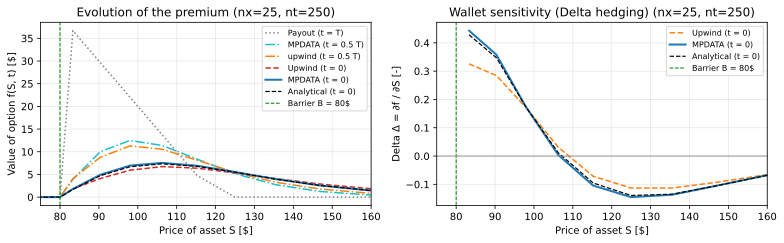

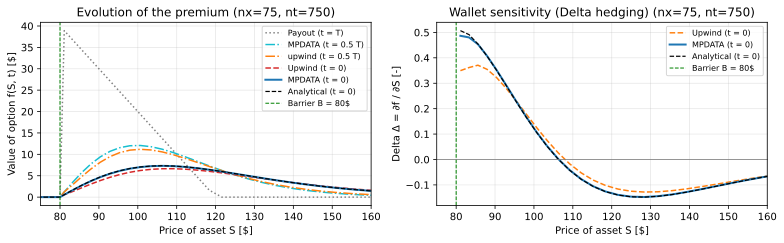

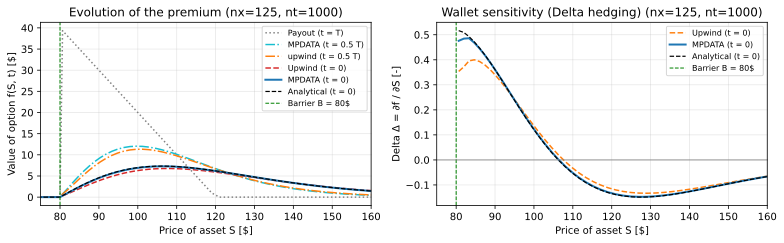

In [6]:
strike_price = 120
barrier_price = 80
volatility = 0.35
risk_free_interest_rate = 0.05
T = 0.5
nx = [25, 75, 125]
nt = [250, 750, 1000]
outfreq = [25, 75, 10]

errors_mpdata = []
errors_upwind = []

for i in range(3):
    integ_MPDATA = DownAndOutPutIntegrator(
        strike_price=strike_price, barrier_price=barrier_price,
        volatility=volatility, risk_free_interest_rate=risk_free_interest_rate,
        nx=nx[i]
    )
    integ_upwind = DownAndOutPutIntegrator(
        strike_price=strike_price, barrier_price=barrier_price,
        volatility=volatility, risk_free_interest_rate=risk_free_interest_rate,
        nx=nx[i], options=Options(n_iters=1)
    )
    
    output_MPDATA = integ_MPDATA(nt=nt[i], T=T, outfreq=outfreq[i])
    output_upwind = integ_upwind(nt=nt[i], T=T, outfreq=outfreq[i])
    
    exact = AnalyticalDownAndOutPutSolver(
        integ_MPDATA.S, strike_price, barrier_price, T, risk_free_interest_rate, volatility
    )
    errors_mpdata.append(np.sqrt(np.mean((output_MPDATA[-1] - exact)**2)))
    errors_upwind.append(np.sqrt(np.mean((output_upwind[-1] - exact)**2)))
    
    plot_results(integ_MPDATA, output_MPDATA, output_upwind, nx[i], nt[i])

assert errors_mpdata[-1] < errors_upwind[-1], "MPDATA should have a smaller error than upwind"
assert errors_mpdata[-1] < errors_mpdata[0], "Error should get smaller with increase of nx"
assert errors_mpdata[-1] < 0.25, f"Error too large of L2 for nx=125: {errors_mpdata[-1]:.4f}"
assert np.all(output_MPDATA[-1] >= 0.0), "Price of asset cannot be negative"

## 4. Wyniki: ewolucja wartości opcji i wrażliwość Delta (dla nx=200, nt=4000, outfreq=200)

In [ ]:
from matplotlib.animation import FuncAnimation, PillowWriter

dt_frame = T / (len(output_MPDATA) - 1)
y_max = np.max(output_MPDATA[0]) * 1.1
S = integ_MPDATA.S
S_plot = np.concatenate(([60.0, barrier_price], S))
pad_zeros = lambda arr: np.concatenate(([0.0, 0.0], arr))
analytical_price = AnalyticalDownAndOutPutSolver(S, strike_price, barrier_price, T, risk_free_interest_rate, volatility)

fig, ax = pyplot.subplots(figsize=(7, 4))

def update(frame):
    ax.clear()
    tau = frame * dt_frame
    t_remaining = T - tau
    ax.fill_between(S_plot, pad_zeros(output_MPDATA[frame]), color='tab:blue', alpha=0.25)
    ax.plot(S_plot, pad_zeros(output_MPDATA[frame]), color='tab:blue', linewidth=2, label='MPDATA')
    ax.plot(S_plot, pad_zeros(output_upwind[frame]), color='tab:orange', linestyle='--', linewidth=1.5, label='upwind')
    ax.plot(S_plot, pad_zeros(analytical_price), color='black', linestyle=':', linewidth=1.2, label='Analityczne (t = 0)')
    ax.axvline(barrier_price, color='green', linestyle='--', linewidth=1.5, label=f'Bariera B = {barrier_price}$')
    ax.set_xlim(65, 200)
    ax.set_ylim(-1, y_max)
    ax.set_xlabel('Cena aktywa S [$]')
    ax.set_ylabel('Wartość opcji V [$]')
    ax.set_title(f'Ewolucja wartości opcji (nx=125, nt=1000) – pozostało {t_remaining:.3f} roku')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right')

anim = FuncAnimation(fig, update, frames=len(output_MPDATA), interval=80)
anim.save('animation.gif', writer=PillowWriter(fps=15))
pyplot.close(fig)

### Wnioski
* **Zbieżność na siatce:** Już przy $n_x = 25$ widać, jak silna dyfuzja numeryczna schematu `upwind` zaniża cenę opcji i spłaszcza krzywą $\Delta$. Wraz ze wzrostem rozdzielczości ($n_x = 75 \to 125$) `MPDATA` niemal idealnie pokrywa się z rozwiązaniem analitycznym, podczas gdy `upwind` nadal wyraźnie odstaje w okolicy maksimum ($S \approx 95\$$) oraz przy barierze $B = 80\$$.
* **Dodatek:** Pełny przebieg czasowy ewolucji wartości opcji dla najgęstszej siatki ($n_x = 125, n_t = 1000$) został wygenerowany jako osobny artefakt `animacja.gif`.

# TODO
* asercje i testy
* mniej toerii (prawie wgle, tylko wzmianka o tym co zrobiłem)
* wyrzucić tłumaczenie w kodzie, tylko dać akapity/paragrafy z .md tam gdzie ma sens i tyle
* zdecydowanie prstsze słownictwo i o wiele mniej skomplikowane i zdecydowanie mniej długie, ma być więcej czillu
* zmniejszyć wykresy, żeby wszystkie się mieściło na 2 stronach (teraz jest 2 i pół/ 2 i 3/4) (bez TODO tyle zajmuje)
* wygeneowac animację jako artefakt, teraz w pdf jest pp <IPython.core.display.HTML object> zamist animcacji, może być aniamacja jako osobny artefakt, ale żeby było wszsytko okej w sprawozdaniu związane z tym